# Bài 6 (Trang 27): Phân lớp dữ liệu Mushroom
**Sinh viên:** Trần Nhất Long - 6451071042

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

print("Trần Nhất Long - 6451071042")
data = pd.read_csv("mushrooms.csv")
print("Kích thước dữ liệu:", data.shape)
data.info()
data.head()

Trần Nhất Long - 6451071042
Kích thước dữ liệu: (8124, 23)
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## Câu 4: Tách dữ liệu thành thuộc tính đầu vào (`features`) và thuộc tính quyết định (`class`)

In [2]:
print("Trần Nhất Long - 6451071042")
features = data.drop("class", axis=1)
labels = data["class"]
print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân bố nhãn class (e=edible, p=poisonous):")
print(labels.value_counts())

Trần Nhất Long - 6451071042
Kích thước features: (8124, 22)
Kích thước labels: (8124,)
Phân bố nhãn class (e=edible, p=poisonous):
class
e    4208
p    3916
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [3]:
print("Trần Nhất Long - 6451071042")
non_numeric_cols = features.select_dtypes(exclude=["int64", "float64"]).columns
print("Số cột không phải dạng số:", len(non_numeric_cols))
print(list(non_numeric_cols))

features_onehot = pd.get_dummies(features, columns=non_numeric_cols)
print("Kích thước sau one-hot encoding:", features_onehot.shape)
features_onehot.head()

Trần Nhất Long - 6451071042
Số cột không phải dạng số: 22
['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
Kích thước sau one-hot encoding: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,True,False,False,False,True,...,True,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False


## Câu 6: Chia dữ liệu đầu vào thành 70% huấn luyện và 30% kiểm thử

In [4]:
print("Trần Nhất Long - 6451071042")
X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

Trần Nhất Long - 6451071042
X_train: (5686, 117) | y_train: (5686,)
X_test: (2438, 117) | y_test: (2438,)


## Câu 7: Xây dựng cây ID3 (`criterion='entropy'`), ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042
Accuracy (ID3): 1.0
Report (ID3):
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



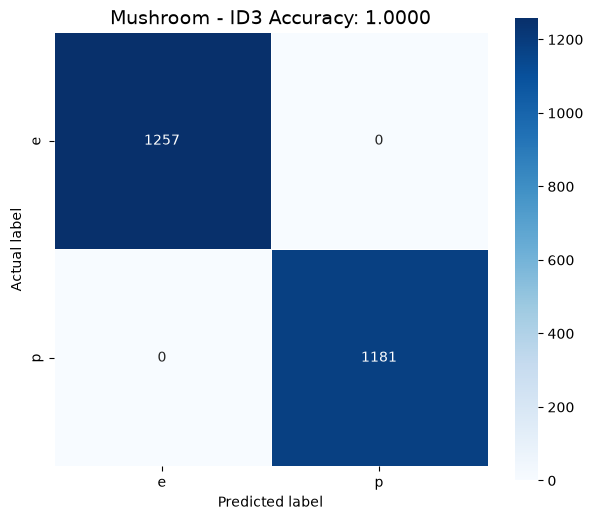

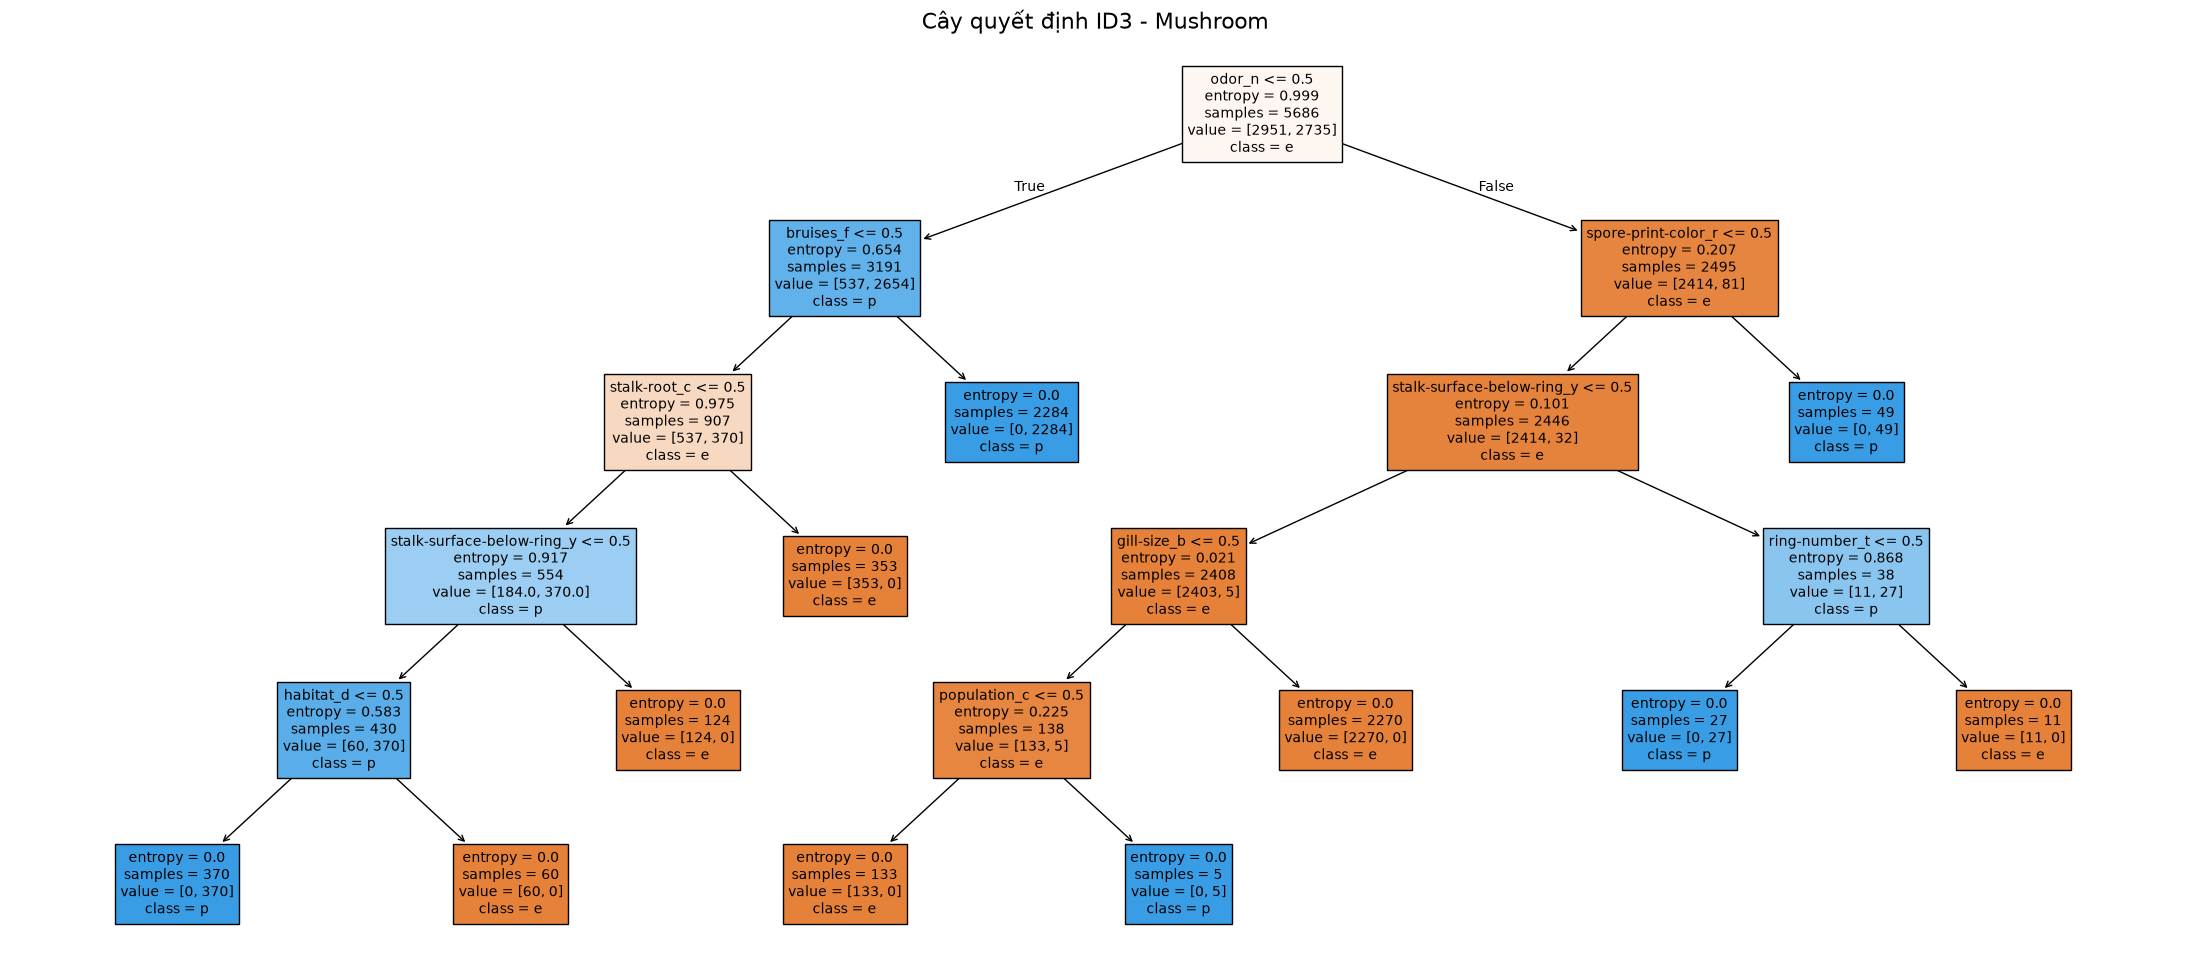

In [5]:
print("Trần Nhất Long - 6451071042")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy (ID3):", id3_score)
print("Report (ID3):\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Blues",
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Mushroom - ID3 Accuracy: {id3_score:.4f}", size=14)
plt.show()

fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(
    clf_id3,
    feature_names=list(features_onehot.columns),
    class_names=list(clf_id3.classes_),
    filled=True,
    fontsize=10,
)
plt.title("Cây quyết định ID3 - Mushroom", fontsize=16)
plt.savefig("decision_tree_id3_mushroom.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 8: Xây dựng cây CART (`criterion='gini'`), ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042
Accuracy (CART): 1.0
Report (CART):
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



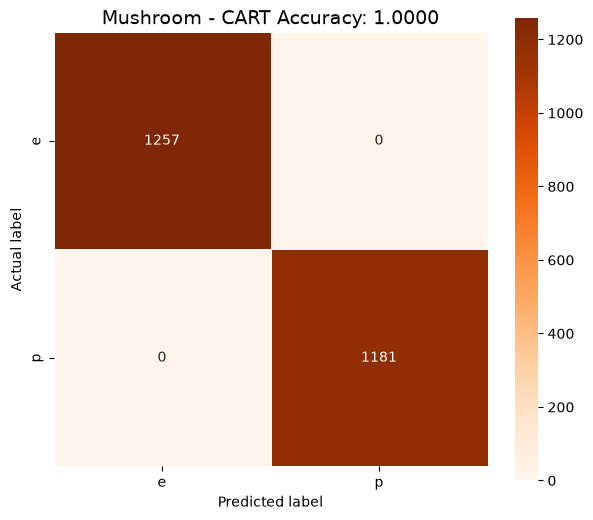

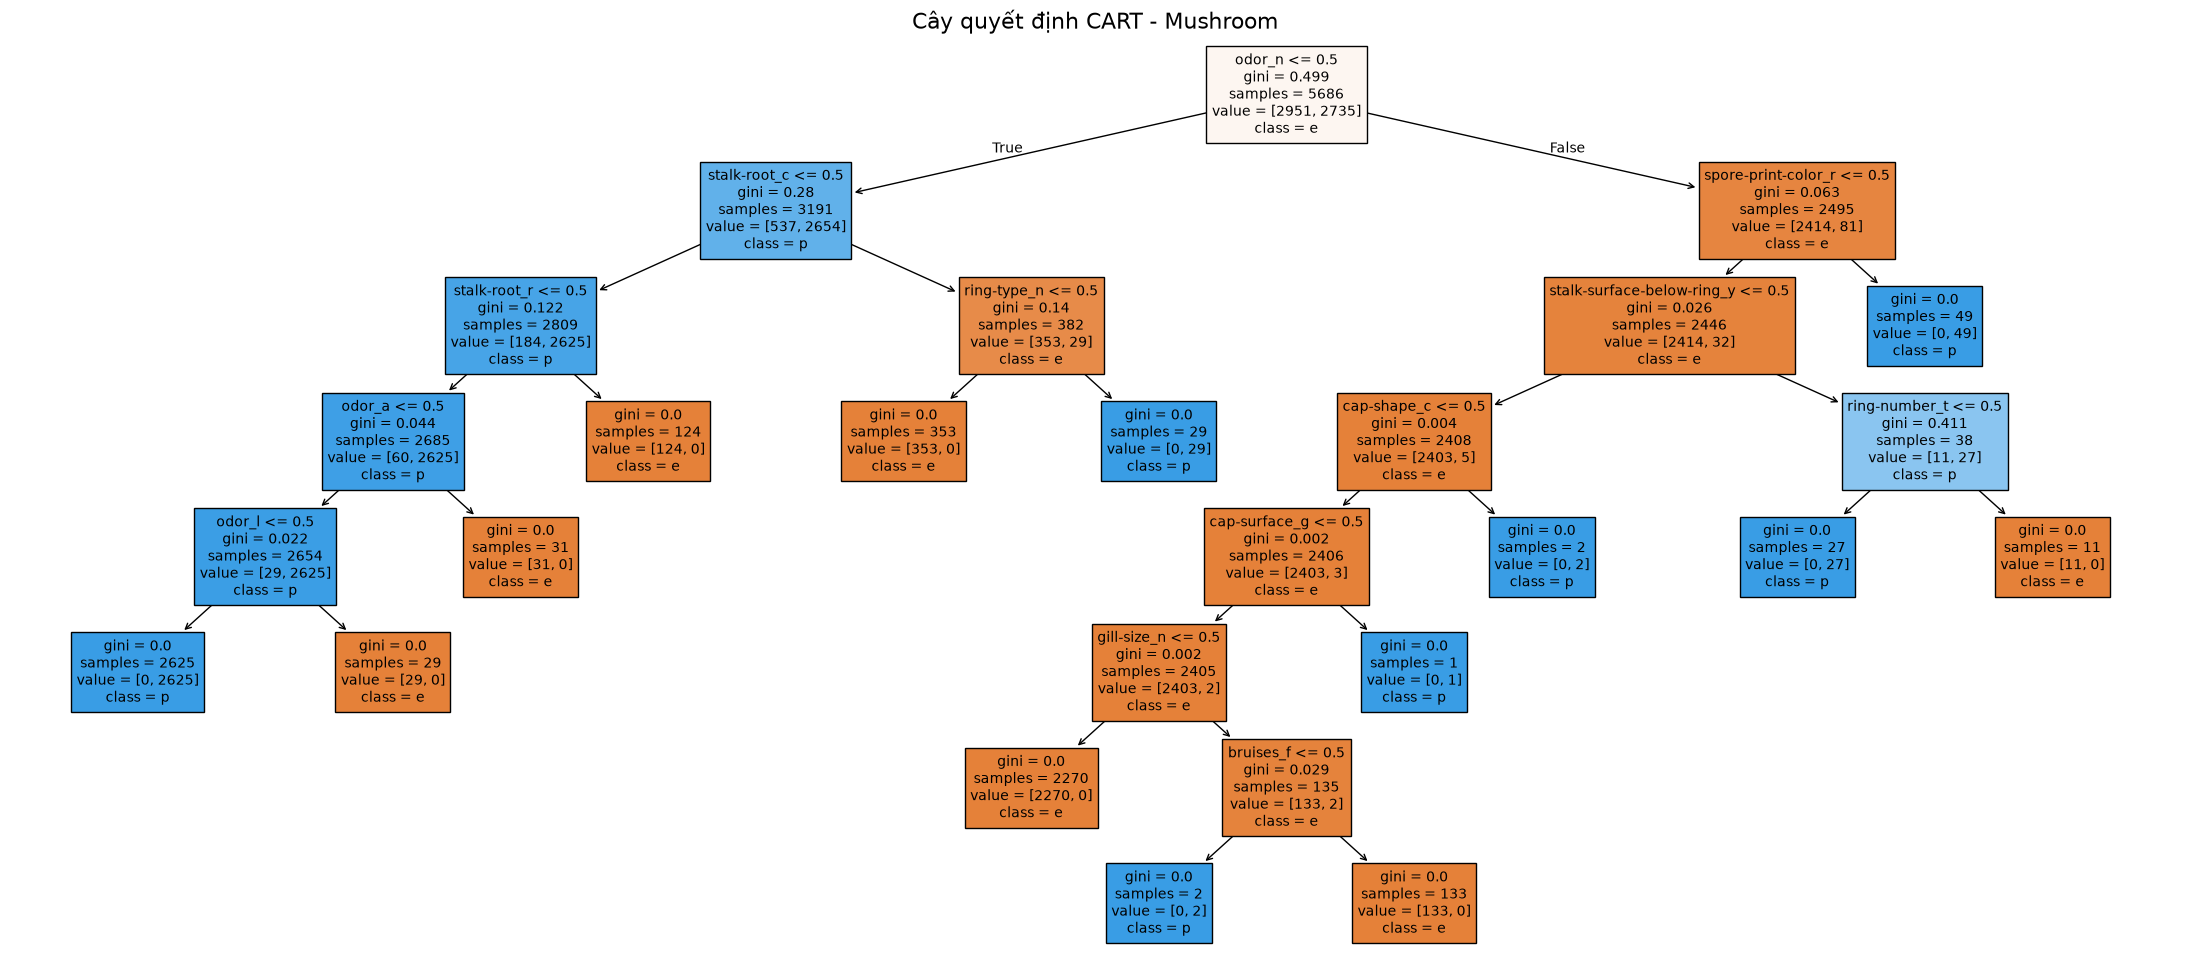

In [6]:
print("Trần Nhất Long - 6451071042")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy (CART):", cart_score)
print("Report (CART):\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Oranges",
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Mushroom - CART Accuracy: {cart_score:.4f}", size=14)
plt.show()

fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(
    clf_cart,
    feature_names=list(features_onehot.columns),
    class_names=list(clf_cart.classes_),
    filled=True,
    fontsize=10,
)
plt.title("Cây quyết định CART - Mushroom", fontsize=16)
plt.savefig("decision_tree_cart_mushroom.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`) và kiểm tra kết quả

Trần Nhất Long - 6451071042
Accuracy (Naïve Bayes): 0.9643150123051681
Report (Naïve Bayes):
               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



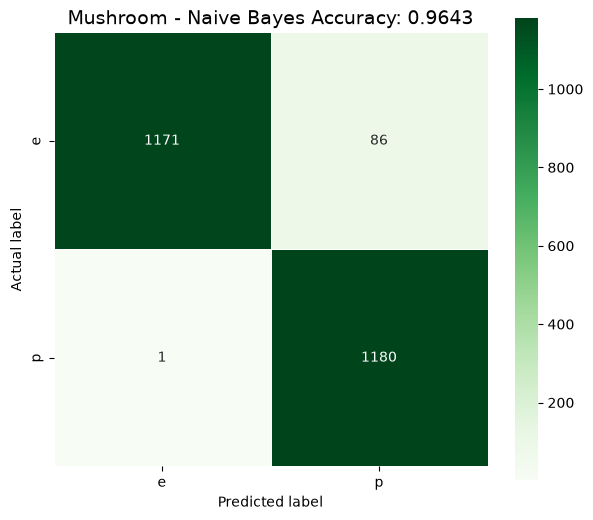

In [7]:
print("Trần Nhất Long - 6451071042")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy (Naïve Bayes):", bayes_score)
print("Report (Naïve Bayes):\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Greens",
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Mushroom - Naive Bayes Accuracy: {bayes_score:.4f}", size=14)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

Trần Nhất Long - 6451071042
                 Mô hình  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
           ID3 (Entropy)  1.000000           1.000000        1.000000          1.000000
             CART (Gini)  1.000000           1.000000        1.000000          1.000000
Naïve Bayes (GaussianNB)  0.964315           0.965608        0.965368          0.964315


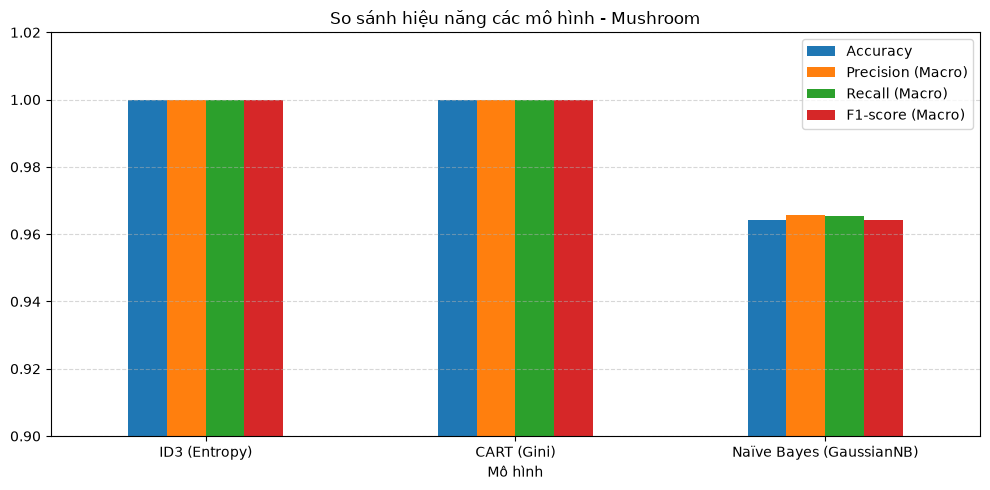


Nhận xét:
- Cả hai cây quyết định ID3 và CART đều đạt độ chính xác tuyệt đối 100% (Accuracy = 1.0) chỉ với cây có độ sâu nhỏ.
- GaussianNB đạt độ chính xác thấp hơn một chút (~96.4%) do dữ liệu đầu vào là các vector nhị phân one-hot không tuân theo phân phối chuẩn.


In [8]:
print("Trần Nhất Long - 6451071042")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naïve Bayes (GaussianNB)", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (Macro)": metrics.precision_score(y_test, pred, average="macro"),
        "Recall (Macro)": metrics.recall_score(y_test, pred, average="macro"),
        "F1-score (Macro)": metrics.f1_score(y_test, pred, average="macro"),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))

df_compare.set_index("Mô hình").plot(kind="bar", figsize=(10, 5), ylim=(0.9, 1.02))
plt.title("So sánh hiệu năng các mô hình - Mushroom")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("\nNhận xét:")
print("- Cả hai cây quyết định ID3 và CART đều đạt độ chính xác tuyệt đối 100% (Accuracy = 1.0) chỉ với cây có độ sâu nhỏ.")
print("- GaussianNB đạt độ chính xác thấp hơn một chút (~96.4%) do dữ liệu đầu vào là các vector nhị phân one-hot không tuân theo phân phối chuẩn.")